# Assignment 6: Multiple Linear Regression
## Part B - Model Fitting, Diagnostics, and Refinement

This notebook follows the seven-step workflow given in the assignment. The response variable is `y`, and the predictors are `x1` to `x11`.

### Step 1: Import libraries and set reproducible options

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:.4f}')
RANDOM_STATE = 42
ALPHA = 0.05
VIF_LIMIT = 10

### Step 1: Load and explore the dataset

In [32]:
data = pd.read_csv('data_MLR.csv')
predictor_names = [column for column in data.columns if column != 'y']

print('Shape:', data.shape)
print('Missing values:', data.isna().sum().sum())
display(data.head())
display(data.describe().T)

Shape: (1000, 12)
Missing values: 0


,y,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11
0,-123.7413,-6.3490,-4.8418,-16.9372,-43.2978,10.4776,2.5514,3.7569,3.5594,-11.6000,17.7512,-7.6324
1,-80.0749,-0.1461,-6.4076,-5.0821,-32.5585,9.2169,6.7761,3.7121,4.6798,-11.6502,8.2367,-29.9829
2,-80.7151,2.1652,-7.5311,0.9386,-31.1674,8.5810,0.1758,6.1796,6.8437,-11.9329,14.2582,-17.0099
3,-31.2757,0.6277,-4.7784,0.5089,-22.0441,10.2826,4.4290,15.3574,7.5736,-11.2862,18.5269,-4.1315
4,51.9095,5.6641,-11.0249,13.5372,-38.1176,10.7270,4.1875,6.4486,6.3851,-11.3668,15.8749,-12.0518


,count,mean,std,min,25%,50%,75%,max
y,1000.0000,-40.6231,59.7796,-179.5875,-83.2354,-48.5021,-10.3811,186.1486
x1,1000.0000,-0.0274,3.1565,-11.1998,-2.1409,-0.1480,2.0997,9.8409
x2,1000.0000,-4.9684,1.9614,-11.6569,-6.1522,-4.9245,-3.5707,1.3163
x3,1000.0000,-0.0890,7.4716,-23.4502,-5.2504,-0.2009,5.0283,24.8725
x4,1000.0000,-24.9234,13.7667,-66.8216,-34.0970,-24.4518,-15.7012,18.7524
x5,1000.0000,11.1424,2.4742,7.2078,9.2012,10.6433,12.6375,23.1972
x6,1000.0000,0.4333,4.6423,-15.1424,-2.4335,1.0482,3.6532,12.1713
x7,1000.0000,6.3103,6.9104,-21.2538,1.4541,6.5501,11.2642,24.3706
x8,1000.0000,4.0504,3.1225,-6.0900,1.8562,4.0688,6.2226,14.7882
x9,1000.0000,-10.0296,2.0496,-17.1675,-11.4553,-10.0198,-8.5575,-2.7798


The file is loaded directly from the workspace. The shape and missing-value check confirm that the expected response and predictor columns are available before modelling.

### Step 1: Split the data and scale predictors using training data only

In [33]:
X = data[predictor_names]
y = data['y']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=predictor_names,
    index=X_train_raw.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=predictor_names,
    index=X_test_raw.index
)

print('Training observations:', len(X_train_scaled))
print('Test observations:', len(X_test_scaled))
print('Training means after scaling:')
display(X_train_scaled.mean().round(6).to_frame('mean').T)

Training observations: 800
Test observations: 200
Training means after scaling:


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11
mean,0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000


The split is reproducible. `StandardScaler` is fitted only on the training predictors; the test predictors are transformed with the already-fitted scaler to prevent test-set information leakage.

### Step 2: Fit the full multiple linear regression model

In [34]:
def fit_ols(features, row_index=None):
    if row_index is None:
        row_index = X_train_scaled.index
    design_matrix = sm.add_constant(X_train_scaled.loc[row_index, features], has_constant='add')
    return sm.OLS(y_train.loc[row_index], design_matrix).fit()

current_features = predictor_names.copy()
full_model = fit_ols(current_features)

print('Full model adjusted R-squared:', round(full_model.rsquared_adj, 4))
print('Full model F-test p-value:', f'{full_model.f_pvalue:.6g}')
display(pd.DataFrame({'coefficient': full_model.params, 'p_value': full_model.pvalues}))

Full model adjusted R-squared: 0.1933
Full model F-test p-value: 5.85968e-33


,coefficient,p_value
const,-41.0891,0.0000
x1,-231.1563,0.5348
x2,-236.8398,0.5370
x3,13.0985,0.0002
x4,353.4246,0.5179
x5,5.9232,0.0019
x6,6.3423,0.0009
x7,-3.2199,0.0901
x8,2.2450,0.5121
x9,48.7460,0.1432


The full model provides the baseline. Adjusted R-squared is used because it penalises unnecessary predictors, while coefficient p-values test whether each predictor contributes information after the other predictors are included.

### Step 3: Calculate VIF and remove serious multicollinearity iteratively

In [35]:
def calculate_vif(features, row_index=None):
    if row_index is None:
        row_index = X_train_scaled.index
    values = X_train_scaled.loc[row_index, features]
    return pd.DataFrame({
        'feature': features,
        'VIF': [variance_inflation_factor(values.values, i) for i in range(len(features))]
    }).sort_values('VIF', ascending=False).reset_index(drop=True)

vif_log = []
vif_table = calculate_vif(current_features)

while vif_table['VIF'].max() > VIF_LIMIT and len(current_features) > 1:
    feature_to_drop = vif_table.iloc[0]['feature']
    highest_vif = vif_table.iloc[0]['VIF']
    current_features.remove(feature_to_drop)
    model_after_drop = fit_ols(current_features)
    vif_log.append({
        'dropped_feature': feature_to_drop,
        'VIF_before_drop': highest_vif,
        'adjusted_R2_after_drop': model_after_drop.rsquared_adj,
        'remaining_features': ', '.join(current_features)
    })
    vif_table = calculate_vif(current_features)

print('VIF table for the final VIF-controlled feature set:')
display(vif_table)
print('VIF refinement log:')
display(pd.DataFrame(vif_log) if vif_log else pd.DataFrame({'message': ['No VIF exceeded 10']}))

VIF table for the final VIF-controlled feature set:


,feature,VIF
0,x1,3.4243
1,x3,3.4225
2,x8,3.2838
3,x10,3.2667
4,x9,1.0183
5,x6,1.0156
6,x7,1.0105
7,x2,1.0075
8,x5,1.0046


VIF refinement log:


,dropped_feature,VIF_before_drop,adjusted_R2_after_drop,remaining_features
0,x4,83844.2095,0.1939,"x1, x2, x3, x5, x6, x7, x8, x9, x10, x11"
1,x11,1436.8334,0.1928,"x1, x2, x3, x5, x6, x7, x8, x9, x10"


A predictor is removed only when its VIF is greater than 10, starting with the largest VIF. After each removal the model and all VIF values are recomputed. This makes the decision conservative and documents the adjusted R-squared after every drop.

### Step 4: Detect influential observations with Cook's Distance and DFFITS

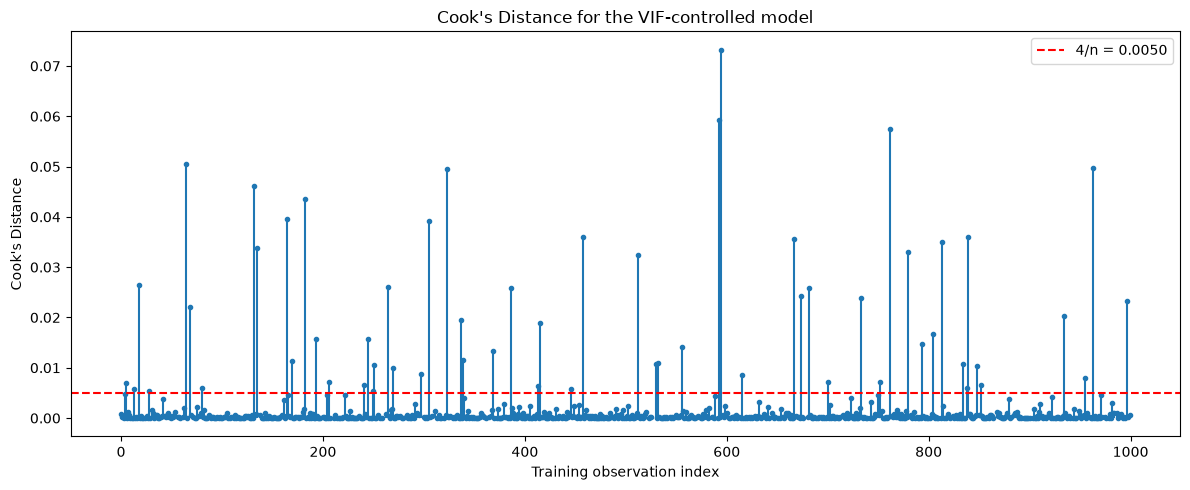

Cooks Distance threshold: 0.005
DFFITS threshold: 0.22361
Observations flagged by both diagnostics: [305, 963, 323, 5, 250, 934, 594, 530, 532, 135, 164, 28, 193, 852, 169, 813, 132, 264, 18, 182, 368, 615, 793, 68, 446, 512, 834, 245, 667, 780, 762, 297, 415, 752, 386, 556, 733, 206, 848, 804, 839, 674, 592, 838, 64, 337, 251, 996, 269, 80, 339, 241, 13, 681, 955, 413, 458, 700]


In [36]:
diagnostic_model = fit_ols(current_features)
influence = diagnostic_model.get_influence()
influence_frame = influence.summary_frame()
n_train = len(y_train)
parameter_count = len(diagnostic_model.params)
cooks_threshold = 4 / n_train
dffits_threshold = 2 * np.sqrt(parameter_count / n_train)

diagnostics = pd.DataFrame({
    'observation': y_train.index,
    'cooks_distance': influence_frame['cooks_d'].values,
    'dffits': influence_frame['dffits_internal'].values,
    'leverage': influence.hat_matrix_diag,
})
diagnostics['flagged_by_cooks'] = diagnostics['cooks_distance'] > cooks_threshold
diagnostics['flagged_by_dffits'] = diagnostics['dffits'].abs() > dffits_threshold
diagnostics['flagged_by_both'] = diagnostics['flagged_by_cooks'] & diagnostics['flagged_by_dffits']

plt.figure(figsize=(12, 5))
plt.stem(diagnostics['observation'], diagnostics['cooks_distance'], markerfmt='.', basefmt=' ')
plt.axhline(cooks_threshold, color='red', linestyle='--', label=f'4/n = {cooks_threshold:.4f}')
plt.title("Cook's Distance for the VIF-controlled model")
plt.xlabel('Training observation index')
plt.ylabel("Cook's Distance")
plt.legend()
plt.tight_layout()
plt.show()

flagged_indices = diagnostics.loc[diagnostics['flagged_by_both'], 'observation'].tolist()
print('Cooks Distance threshold:', round(cooks_threshold, 5))
print('DFFITS threshold:', round(dffits_threshold, 5))
print('Observations flagged by both diagnostics:', flagged_indices)

Cook's Distance identifies observations that can change the fitted model, while DFFITS focuses on the change in that observation's fitted value. The code reports both thresholds and uses the intersection of the two flags for a cautious influence decision. A flagged observation is not automatically deleted.

### Step 4: Remove influential observations only when the fit improves

In [37]:
model_before_influence = fit_ols(current_features)
rows_after_influence = [index for index in y_train.index if index not in flagged_indices]
model_without_influence = fit_ols(current_features, rows_after_influence)

if flagged_indices and model_without_influence.rsquared_adj > model_before_influence.rsquared_adj:
    removed_observations = flagged_indices
    active_train_indices = rows_after_influence
    influence_decision = 'Removed because the adjusted R-squared improved.'
else:
    removed_observations = []
    active_train_indices = list(y_train.index)
    influence_decision = 'No observations removed because no common flags existed or adjusted R-squared did not improve.'

current_model = fit_ols(current_features, active_train_indices)
print(influence_decision)
print('Removed observations:', removed_observations)
print('Adjusted R-squared before influence check:', round(model_before_influence.rsquared_adj, 4))
print('Adjusted R-squared after influence check:', round(current_model.rsquared_adj, 4))

Removed because the adjusted R-squared improved.
Removed observations: [305, 963, 323, 5, 250, 934, 594, 530, 532, 135, 164, 28, 193, 852, 169, 813, 132, 264, 18, 182, 368, 615, 793, 68, 446, 512, 834, 245, 667, 780, 762, 297, 415, 752, 386, 556, 733, 206, 848, 804, 839, 674, 592, 838, 64, 337, 251, 996, 269, 80, 339, 241, 13, 681, 955, 413, 458, 700]
Adjusted R-squared before influence check: 0.1928
Adjusted R-squared after influence check: 0.8367


Only observations flagged by both diagnostics are considered. They are removed only if adjusted R-squared increases after refitting. If the criterion is not met, the observations remain in the model and the decision is documented as no removal.

### Step 5: Refine the feature set using coefficient p-values and adjusted R-squared

In [38]:
stepwise_log = []
while len(current_features) > 1:
    current_model = fit_ols(current_features, active_train_indices)
    predictor_pvalues = current_model.pvalues.drop('const')
    highest_pvalue_feature = predictor_pvalues.idxmax()
    highest_pvalue = predictor_pvalues.max()

    if highest_pvalue <= ALPHA:
        stepwise_log.append({
            'action': 'stop',
            'feature': '',
            'p_value': highest_pvalue,
            'adjusted_R2': current_model.rsquared_adj,
            'reason': 'All remaining predictors are significant'
        })
        break

    trial_features = [feature for feature in current_features if feature != highest_pvalue_feature]
    trial_model = fit_ols(trial_features, active_train_indices)
    stepwise_log.append({
        'action': 'drop',
        'feature': highest_pvalue_feature,
        'p_value': highest_pvalue,
        'adjusted_R2': trial_model.rsquared_adj,
        'reason': 'Highest p-value above 0.05'
    })

    if trial_model.rsquared_adj >= current_model.rsquared_adj:
        current_features = trial_features
    else:
        stepwise_log.append({
            'action': 'stop',
            'feature': highest_pvalue_feature,
            'p_value': highest_pvalue,
            'adjusted_R2': current_model.rsquared_adj,
            'reason': 'Stopped because adjusted R-squared would decrease'
        })
        break

final_model = fit_ols(current_features, active_train_indices)
stepwise_log_table = pd.DataFrame(stepwise_log)
display(stepwise_log_table)
print('Retained features:', current_features)

,action,feature,p_value,adjusted_R2,reason
0,drop,x10,0.6529,0.8369,Highest p-value above 0.05
1,drop,x9,0.3783,0.8370,Highest p-value above 0.05
2,stop,,0.0298,0.8370,All remaining predictors are significant


Retained features: ['x1', 'x2', 'x3', 'x5', 'x6', 'x7', 'x8']


At each iteration, the least statistically useful predictor is the one with the largest p-value above 0.05. It is removed only when adjusted R-squared does not decrease. The log records the feature, p-value, adjusted R-squared, and the stopping reason.

### Step 6: Check LINE assumptions with residual plots

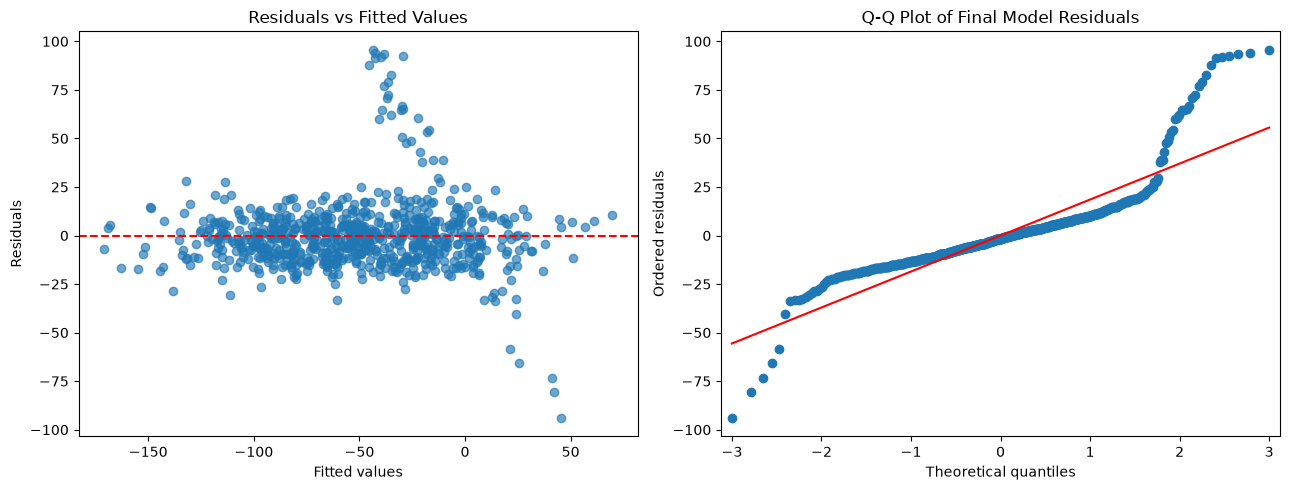

In [39]:
final_fitted_values = final_model.fittedvalues
final_residuals = final_model.resid

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(final_fitted_values, final_residuals, alpha=0.65)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted Values')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')


sm.qqplot(final_residuals, line='s', ax=axes[1])
axes[1].set_title('Q-Q Plot of Final Model Residuals')
axes[1].set_xlabel('Theoretical quantiles')
axes[1].set_ylabel('Ordered residuals')

plt.tight_layout()
plt.show()

For the residuals-versus-fitted plot, a random horizontal cloud around zero supports linearity and approximately equal variance. For the Q-Q plot, points close to the reference line support approximate normality. These are visual checks, so any clear curvature, funnel shape, or strong tail departure should be reported as a possible assumption violation.

### Step 7: Evaluate the final model on the held-out test set

In [40]:
test_design_matrix = sm.add_constant(X_test_scaled[current_features], has_constant='add')
test_predictions = final_model.predict(test_design_matrix)

evaluation_table = pd.DataFrame({
    'metric': ['Training adjusted R-squared', 'Test MAE', 'Test RMSE', 'Test R-squared'],
    'value': [
        final_model.rsquared_adj,
        mean_absolute_error(y_test, test_predictions),
        np.sqrt(mean_squared_error(y_test, test_predictions)),
        r2_score(y_test, test_predictions)
    ]
})
display(evaluation_table)

print('Final model coefficients:')
display(final_model.params.to_frame('coefficient'))
print('Final model p-values:')
display(final_model.pvalues.to_frame('p_value'))

,metric,value
0,Training adjusted R-squared,0.8370
1,Test MAE,25.7071
2,Test RMSE,56.6781
3,Test R-squared,0.1413


Final model coefficients:


,coefficient
const,-53.9590
x1,21.2345
x2,21.7451
x3,15.6365
x5,2.1641
x6,12.2241
x7,-1.5656
x8,1.7933


Final model p-values:


,p_value
const,0.0000
x1,0.0000
x2,0.0000
x3,0.0000
x5,0.0029
x6,0.0000
x7,0.0298
x8,0.0120


The test metrics measure generalisation on data that was not used to fit the model. A test R-squared close to the training adjusted R-squared suggests reasonable generalisation; a much lower test R-squared suggests overfitting or sensitivity to the split. MAE and RMSE are reported in the original units of `y`.

## Final Summary

Run all cells above before completing this summary. Use the printed tables and plots to replace the bracketed values with your observations.

- **Retained features:** The final retained predictors are shown in the Step 5 output as `current_features`.
- **Coefficient interpretation:** A positive coefficient means that, holding all other retained predictors constant, a one-unit increase in that predictor is associated with an increase in `y`. A negative coefficient means an associated decrease in `y`. Because the predictors were standardised, each coefficient describes the expected change in `y` for a one-standard-deviation increase in that predictor, with other predictors held constant.
- **Multicollinearity:** Features with VIF above 10 were removed one at a time, and the VIF table verifies the final feature set.
- **Influence:** Cook's Distance and DFFITS were checked. Observations were removed only when both diagnostics flagged them and adjusted R-squared improved after refitting.
- **Feature refinement:** Predictors with p-values above 0.05 were considered from highest to lowest p-value. Refinement stopped when all remaining predictors were significant or adjusted R-squared would decrease.
- **Model quality:** Compare the final training adjusted R-squared with test R-squared, inspect the residual plots, and report whether the LINE assumptions appear reasonable.